In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project folder and dataset
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:

# Check dataset quality

print("Rows and columns:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nAttrition counts:")
print(df["Attrition"].value_counts())

print("\nAttrition percentages:")
print(
    (df["Attrition"].value_counts(normalize=True) * 100).round(2)
)


Rows and columns: (1470, 35)

Missing values: 0
Duplicate rows: 0

Attrition counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition percentages:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


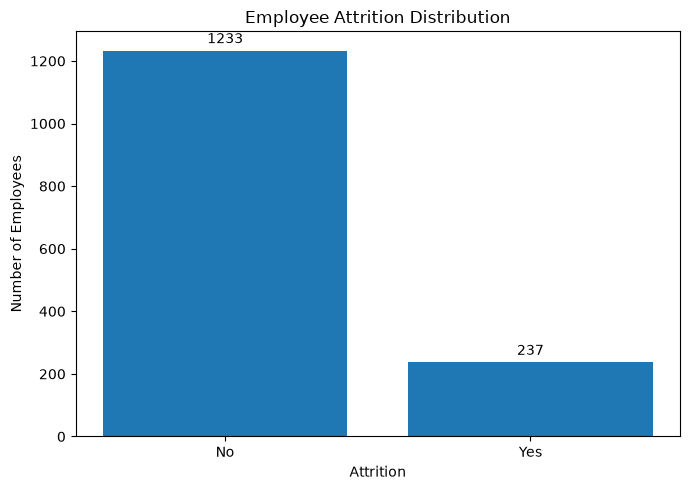

In [3]:

# Visualize employee attrition

attrition_counts = df["Attrition"].value_counts().reindex(
    ["No", "Yes"], fill_value=0
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    attrition_counts.index,
    attrition_counts.values
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.bar_label(bars, padding=3)

plt.tight_layout()
plt.show()


Employee counts by department:


Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,828,133
Sales,354,92


Attrition percentages by department:


Attrition,No,Yes
Department,,
Human Resources,80.95,19.05
Research & Development,86.16,13.84
Sales,79.37,20.63


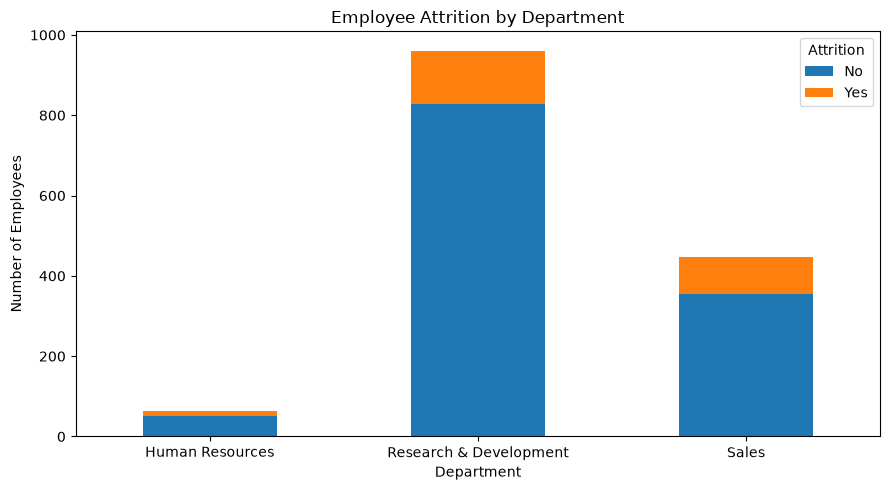

In [4]:

# Analyze employee attrition by department

department_counts = pd.crosstab(
    df["Department"],
    df["Attrition"]
)

print("Employee counts by department:")
display(department_counts)

# Calculate attrition percentages within each department
department_percentages = (
    pd.crosstab(
        df["Department"],
        df["Attrition"],
        normalize="index"
    ) * 100
).round(2)

print("Attrition percentages by department:")
display(department_percentages)

# Create the chart
department_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.legend(title="Attrition")
plt.tight_layout()
plt.show()


Employee counts by overtime status:


Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


Attrition percentages by overtime status:


Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53


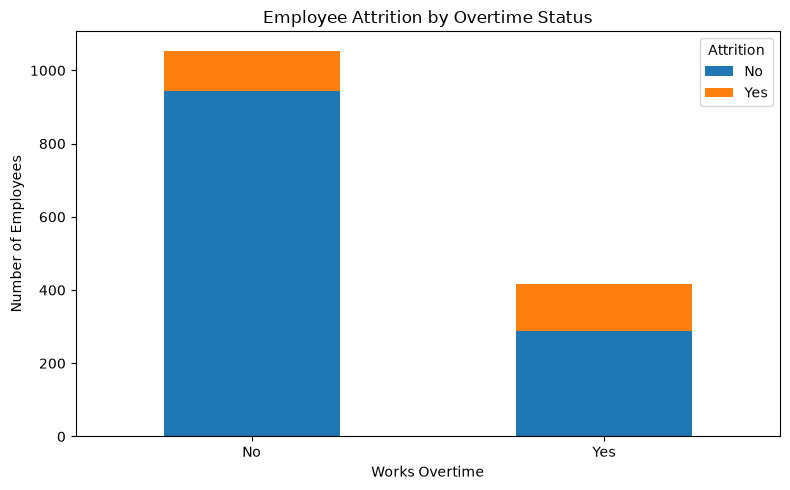

In [5]:

# Analyze employee attrition by overtime status

overtime_counts = pd.crosstab(
    df["OverTime"],
    df["Attrition"]
)

print("Employee counts by overtime status:")
display(overtime_counts)

overtime_percentages = (
    pd.crosstab(
        df["OverTime"],
        df["Attrition"],
        normalize="index"
    ) * 100
).round(2)

print("Attrition percentages by overtime status:")
display(overtime_percentages)

overtime_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Employee Attrition by Overtime Status")
plt.xlabel("Works Overtime")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.legend(title="Attrition")
plt.tight_layout()
plt.show()


Employee counts by job satisfaction:


Attrition,No,Yes
JobSatisfaction,,
1,223,66
2,234,46
3,369,73
4,407,52


Attrition percentages by job satisfaction:


Attrition,No,Yes
JobSatisfaction,,
1,77.16,22.84
2,83.57,16.43
3,83.48,16.52
4,88.67,11.33


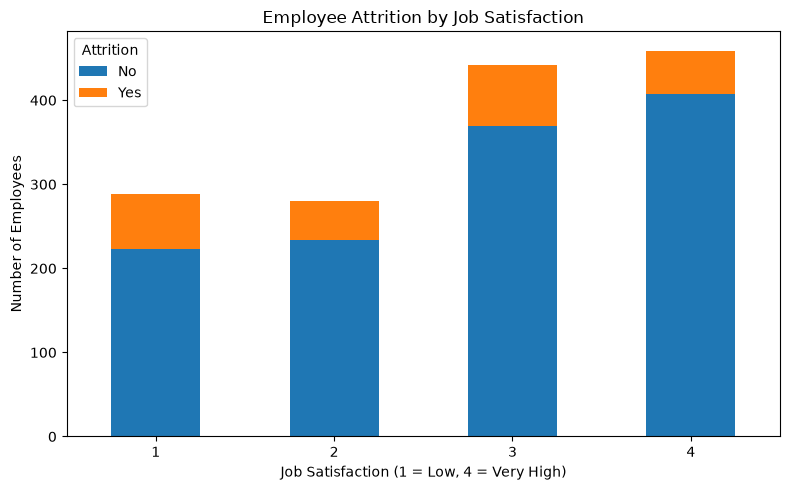

In [6]:

# Analyze attrition by job satisfaction

satisfaction_counts = pd.crosstab(
    df["JobSatisfaction"],
    df["Attrition"]
)

print("Employee counts by job satisfaction:")
display(satisfaction_counts)

satisfaction_percentages = (
    pd.crosstab(
        df["JobSatisfaction"],
        df["Attrition"],
        normalize="index"
    ) * 100
).round(2)

print("Attrition percentages by job satisfaction:")
display(satisfaction_percentages)

satisfaction_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Employee Attrition by Job Satisfaction")
plt.xlabel("Job Satisfaction (1 = Low, 4 = Very High)")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.legend(title="Attrition")
plt.tight_layout()
plt.show()


Employee counts by age group:


Attrition,No,Yes
AgeGroup,,
18-25,79,44
26-35,490,116
36-45,425,43
46-55,200,26
56+,39,8


Attrition percentages by age group:


Attrition,No,Yes
AgeGroup,,
18-25,64.23,35.77
26-35,80.86,19.14
36-45,90.81,9.19
46-55,88.50,11.50
56+,82.98,17.02


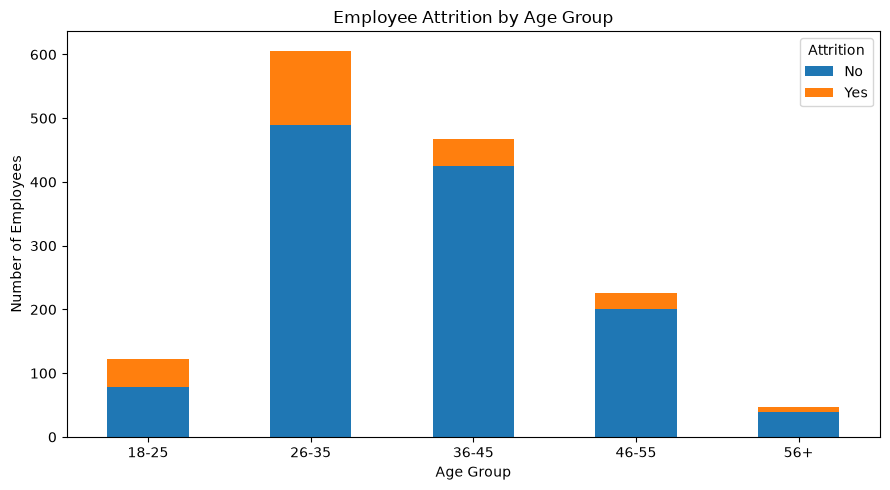

In [7]:

# Analyze attrition by age group

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

age_counts = pd.crosstab(
    df["AgeGroup"],
    df["Attrition"]
)

print("Employee counts by age group:")
display(age_counts)

age_percentages = (
    pd.crosstab(
        df["AgeGroup"],
        df["Attrition"],
        normalize="index"
    ) * 100
).round(2)

print("Attrition percentages by age group:")
display(age_percentages)

age_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Employee Attrition by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.legend(title="Attrition")
plt.tight_layout()
plt.show()
